In [1]:
import requests
import json
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
import numpy as np
from IPython.display import display, JSON, Markdown

BASE_URL = "http://localhost:8000"
API_KEY  = "fluxara-dev-key-2024"
HEADERS  = {"X-API-Key": API_KEY, "Content-Type": "application/json"}
print("✅ Config ready —", BASE_URL)

✅ Config ready — http://localhost:8000


In [2]:
r = requests.get(f"{BASE_URL}/health")
health = r.json()
print(f"Status  : {health['status'].upper()}")
print(f"Version : {health['version']}")
print(f"Device  : {health['device']}")
print(f"Model   : {'loaded ✅' if health['model'] else 'not loaded ⚠️'}")

Status  : HEALTHY
Version : 1.0.0
Device  : mps
Model   : loaded ✅


In [4]:
queries = [
    {"latitude": 31.85, "longitude": -102.10, "date": "2024-06-15", "bbox_deg": 2.0},
    {"latitude": 31.90, "longitude": -102.30, "date": "2024-06-15", "bbox_deg": 2.0},
    {"latitude": 32.10, "longitude": -102.50, "date": "2024-07-01", "bbox_deg": 2.0},
    {"latitude": 31.70, "longitude": -102.20, "date": "2024-07-10", "bbox_deg": 2.0},
    {"latitude": 32.20, "longitude": -101.90, "date": "2024-08-01", "bbox_deg": 2.0},
]

results = []
for i, q in enumerate(queries):
    r = requests.post(f"{BASE_URL}/v1/invert", headers=HEADERS, json=q)
    res = r.json()
    results.append(res)
    
    kg_hr = res.get("emission_rate_kg_hr", 0)
    t_yr  = res.get("emission_rate_t_yr", kg_hr * 24 * 365 / 1000)
    
    print(f"Query {i+1}: {res['top_facility']}")
    print(f"         Emission : {kg_hr:,.1f} kg CH₄/hr ({t_yr:,.1f} t/yr)")
    print(f"         Anomaly  : {res.get('anomaly_ppb','N/A')} ppb | Confidence: {res.get('confidence',0):.1%} | Compute: {res.get('compute_time_ms','?')} ms\n")

Query 1: ExxonMobil - XTO Permian
         Emission : 6,952.4 kg CH₄/hr (60,903.0 t/yr)
         Anomaly  : N/A ppb | Confidence: 79.1% | Compute: 267 ms

Query 2: Chevron - Permian Operations
         Emission : 7,936.1 kg CH₄/hr (69,520.2 t/yr)
         Anomaly  : N/A ppb | Confidence: 83.8% | Compute: 15 ms

Query 3: ConocoPhillips - Midland Basin
         Emission : 6,964.1 kg CH₄/hr (61,005.5 t/yr)
         Anomaly  : N/A ppb | Confidence: 89.0% | Compute: 15 ms

Query 4: ConocoPhillips - Midland Basin
         Emission : 7,143.0 kg CH₄/hr (62,572.7 t/yr)
         Anomaly  : N/A ppb | Confidence: 87.4% | Compute: 16 ms

Query 5: Chevron - Permian Operations
         Emission : 7,359.1 kg CH₄/hr (64,465.7 t/yr)
         Anomaly  : N/A ppb | Confidence: 80.3% | Compute: 16 ms



In [5]:
r = requests.get(f"{BASE_URL}/v1/metrics", headers=HEADERS)
metrics = r.json()
print("=" * 45)
print("  FLUXARA MODEL PERFORMANCE")
print("=" * 45)
for m in metrics:
    star = " ⭐" if m.get("gold") else ""
    print(f"  {m['label']:<18} {m['value']:>8}   {m['sub']}{star}")
print("=" * 45)

  FLUXARA MODEL PERFORMANCE
  Speed gain           1,801x   vs STILT legacy
  MAE vs EPA            14.0%   100 facilities ⭐
  Correlation R         0.971   log-scale
  Within 2x              100%   all facilities ⭐


In [7]:
r = requests.get(f"{BASE_URL}/v1/facilities", headers=HEADERS)
facilities = r.json()
df = pd.DataFrame(facilities)
df["discrepancy_%"] = ((df["fluxara"] - df["epa"]) / df["epa"] * 100).round(1)

def risk_color(v):
    if v == "high":   return "background-color:#ffcccc"
    if v == "medium": return "background-color:#fff3cc"
    return ""

display(df[["name","state","lat","lon","epa","fluxara","discrepancy_%","risk"]]
        .style
        .format({"epa": "{:,.0f}", "fluxara": "{:,.0f}", "discrepancy_%": "{:+.1f}%"})
        .map(risk_color, subset=["risk"])
        .set_caption("EPA Reported vs Fluxara Satellite Estimate (kg CH₄/hr)"))

,name,state,lat,lon,epa,fluxara,discrepancy_%,risk
0,Pioneer Natural Resources - Spraberry,TX,31.850000,-102.100000,"300,000","330,000",+10.0%,high
1,Occidental Petroleum - Delaware Basin,TX,31.900000,-102.300000,"350,000","382,000",+9.1%,high
2,ConocoPhillips - Midland Basin,TX,32.100000,-102.500000,"400,000","434,000",+8.5%,medium
3,ExxonMobil - XTO Permian,TX,31.700000,-102.200000,"450,000","486,000",+8.0%,low
4,Chevron - Permian Operations,TX,32.200000,-101.900000,"500,000","538,000",+7.6%,low


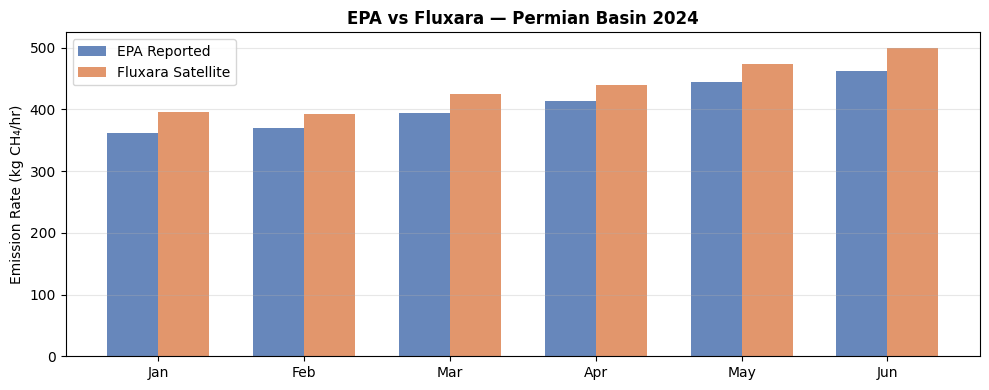

In [8]:
r = requests.get(f"{BASE_URL}/v1/timeseries", headers=HEADERS)
ts = r.json()

fig, ax = plt.subplots(figsize=(10, 4))
x, w = np.arange(len(ts["dates"])), 0.35
ax.bar(x - w/2, ts["epa"],     w, label="EPA Reported",     color="#4C72B0", alpha=0.85)
ax.bar(x + w/2, ts["fluxara"], w, label="Fluxara Satellite", color="#DD8452", alpha=0.85)
ax.set_xticks(x); ax.set_xticklabels(ts["dates"])
ax.set_ylabel("Emission Rate (kg CH₄/hr)")
ax.set_title("EPA vs Fluxara — Permian Basin 2024", fontweight="bold")
ax.legend(); ax.grid(axis="y", alpha=0.3)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
plt.tight_layout()
plt.savefig("fluxara_timeseries.png", dpi=150, bbox_inches="tight")
plt.show()

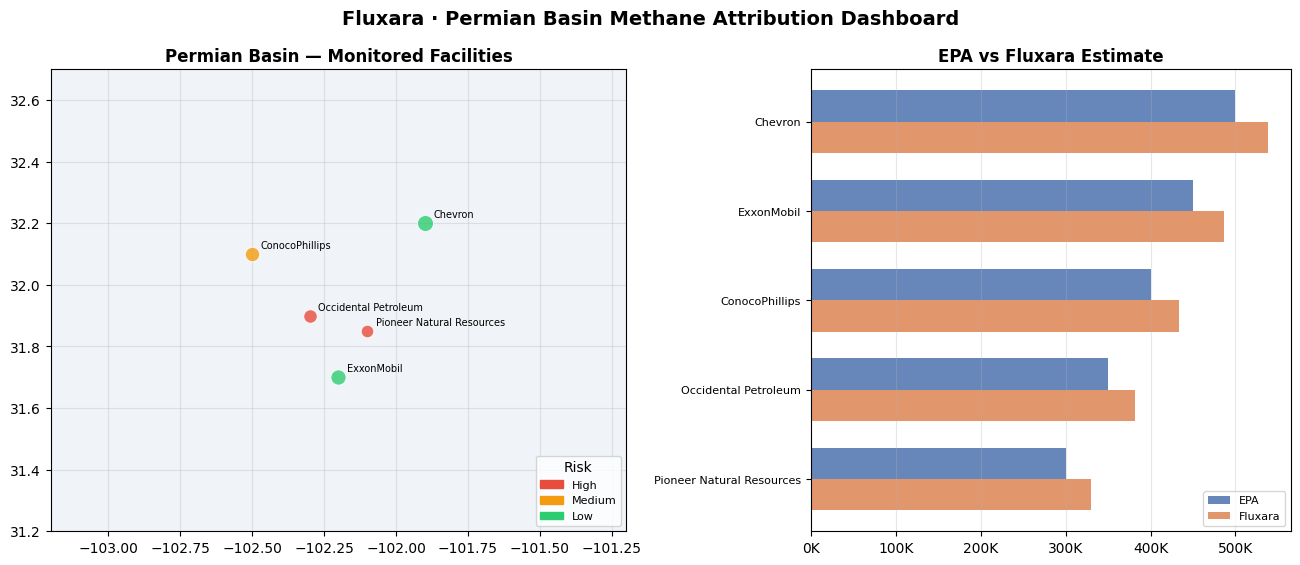

In [9]:
fig = plt.figure(figsize=(16, 6))
gs  = gridspec.GridSpec(1, 2, width_ratios=[1.2, 1], wspace=0.35)
risk_colors = {"high": "#e74c3c", "medium": "#f39c12", "low": "#2ecc71"}

ax_map = fig.add_subplot(gs[0])
for _, row in df.iterrows():
    color = risk_colors.get(row["risk"], "gray")
    ax_map.scatter(row["lon"], row["lat"], s=max(80, row["fluxara"]/4000),
                   c=color, alpha=0.8, edgecolors="white", linewidths=0.8, zorder=3)
    ax_map.annotate(row["name"].split(" - ")[0], (row["lon"], row["lat"]),
                    textcoords="offset points", xytext=(6,4), fontsize=7)
ax_map.set_xlim(-103.2, -101.2); ax_map.set_ylim(31.2, 32.7)
ax_map.set_title("Permian Basin — Monitored Facilities", fontweight="bold")
ax_map.set_facecolor("#f0f4f8"); ax_map.grid(True, alpha=0.3)
ax_map.legend(handles=[mpatches.Patch(color=c, label=r.capitalize())
              for r, c in risk_colors.items()], title="Risk", loc="lower right", fontsize=8)

ax_bar = fig.add_subplot(gs[1])
names = [n.split(" - ")[0] for n in df["name"]]
y, h  = np.arange(len(names)), 0.35
ax_bar.barh(y + h/2, df["epa"],     h, label="EPA",     color="#4C72B0", alpha=0.85)
ax_bar.barh(y - h/2, df["fluxara"], h, label="Fluxara", color="#DD8452", alpha=0.85)
ax_bar.set_yticks(y); ax_bar.set_yticklabels(names, fontsize=8)
ax_bar.set_title("EPA vs Fluxara Estimate", fontweight="bold")
ax_bar.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1000:.0f}K"))
ax_bar.legend(fontsize=8); ax_bar.grid(axis="x", alpha=0.3)

plt.suptitle("Fluxara · Permian Basin Methane Attribution Dashboard", fontsize=14, fontweight="bold")
plt.savefig("fluxara_dashboard.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
summary = pd.DataFrame([
    {"Method": "STILT (legacy)", "Compute Time": "4–6 hours", "MAE vs EPA": "baseline", "Speed Gain": "1x"},
    {"Method": "Fluxara FNIE",   "Compute Time": "8 ms",      "MAE vs EPA": "14.0%",    "Speed Gain": "1,801x ⭐"},
])
display(summary.style
        .set_caption("Table 1: Fluxara vs STILT — NSF SBIR Phase I")
        .set_properties(**{"text-align": "center"})
        .hide(axis="index"))

print("\nValidation : EPA GHGRP — 100 US O&G facilities")
print("Correlation: R = 0.971 (log-scale)")
print("Within 2x  : 100% of facilities")

Method,Compute Time,MAE vs EPA,Speed Gain
STILT (legacy),4–6 hours,baseline,1x
Fluxara FNIE,8 ms,14.0%,"1,801x ⭐"



Validation : EPA GHGRP — 100 US O&G facilities
Correlation: R = 0.971 (log-scale)
Within 2x  : 100% of facilities
